<a href="https://colab.research.google.com/github/nikhilvirdi/Network-Intrusion-Detection-MLP-NSL-KDD/blob/main/notebooks/network_intrusion_detection_mlp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Step 1: Environment Check

Before writing any real code, confirm the Colab VM has the libraries we need
and record their exact versions. This matters because Colab's VM is fresh
every session and could, in principle, come with different pre-installed
versions — if something behaves unexpectedly later, version mismatch is the
first thing to rule out.

In [288]:
import sys
import torch
import pandas as pd
import sklearn
import numpy as np

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
PyTorch: 2.11.0+cpu
pandas: 2.2.2
NumPy: 2.0.2
scikit-learn: 1.6.1


### Step 2: Reproducibility (Random Seed)

Neural network training involves several sources of randomness — most
importantly, how a model's weights are initialized before training starts,
and how data gets shuffled. Without fixing this randomness, running the
exact same code twice can produce two different results, making it
impossible to tell whether a change in outcome came from an actual code
change or just random luck. Setting a fixed seed makes the "randomness"
reproducible — same seed, same sequence of "random" numbers, every run.

In [289]:
import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

### Step 3: Download the Dataset

The Colab VM we connected to is a fresh, empty machine — it has no files
on it except what we put there. NSL-KDD isn't bundled with PyTorch or
scikit-learn, so we need to fetch the raw train and test files from an
external source before pandas can read them. We'll download them directly
onto this VM's disk using a shell command, since Colab VM storage is
temporary and resets when the session ends — this download will need to be
redone if this runtime disconnects (e.g. after long inactivity).

In [290]:
!wget -q https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain+.txt
!wget -q https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTest+.txt
!ls -la *.txt

-rw-r--r-- 1 root root  3441513 Aug  3 11:54 KDDTest+.txt
-rw-r--r-- 1 root root 19109424 Aug  3 11:54 KDDTrain+.txt


### Step 4: Load Data into pandas

These two files are plain CSV data, but critically, they have **no header
row** — the very first line is already a real data record, not column
names. If we load this naively, pandas will silently treat that first
record as the header, corrupting the entire dataset without throwing any
error. We'll fix this by explicitly supplying the 41 official NSL-KDD
feature names, plus two extra columns: `label` (the attack type, as text)
and `difficulty_level` (a score of how hard that record is to classify —
metadata about the record, not a real feature, and must never be fed into
the model as input).

In [291]:
column_names = [
    'duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes',
    'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in',
    'num_compromised', 'root_shell', 'su_attempted', 'num_root',
    'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds',
    'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate',
    'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate',
    'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count',
    'dst_host_same_srv_rate', 'dst_host_diff_srv_rate',
    'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate',
    'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate',
    'dst_host_srv_rerror_rate', 'label', 'difficulty_level'
]

train_df = pd.read_csv('KDDTrain+.txt', names=column_names)
test_df = pd.read_csv('KDDTest+.txt', names=column_names)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

Train shape: (125973, 43)
Test shape: (22544, 43)


### Step 5: Preview the Raw Data

Before deciding how to preprocess anything, we need to see what the data
actually looks like — real values, real types. This tells us which columns
are numeric (something a network can consume directly) versus categorical
text (something that needs converting first), and gives us a first
impression of the data's shape and quality.

In [292]:
train_df.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty_level
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [293]:
train_df.dtypes

,0
duration,int64
protocol_type,object
service,object
flag,object
src_bytes,int64
dst_bytes,int64
land,int64
wrong_fragment,int64
urgent,int64
hot,int64


### Step 6: Label Distribution

The `label` column holds the actual target we're trying to predict —
but it's not simply "normal" vs "attack." It contains dozens of specific
attack names. Before deciding how to frame this as a classification problem
(binary, or multi-class, or attack categories), we need to see exactly what
values exist and how skewed their counts are — this directly affects our
choice of loss function later.

In [294]:
train_df['label'].value_counts()

,count
label,
normal,67343
neptune,41214
satan,3633
ipsweep,3599
portsweep,2931
smurf,2646
nmap,1493
back,956
teardrop,892


### Step 7: Test Set Label Check

Before finalizing the 5-class framing, we need to confirm two things on
the test set: what labels actually appear there, and specifically which
attack types show up in test but were never seen during training. This is
the concrete generalization gap NSL-KDD is known for — a model that only
memorizes training patterns will struggle precisely on these unseen types.

In [295]:
train_labels = set(train_df['label'].unique())
test_labels = set(test_df['label'].unique())

print("Labels in train:", len(train_labels))
print("Labels in test:", len(test_labels))
print("\nIn test but NOT in train (unseen attacks):")
print(test_labels - train_labels)

Labels in train: 23
Labels in test: 38

In test but NOT in train (unseen attacks):
{'snmpgetattack', 'httptunnel', 'xterm', 'mscan', 'xlock', 'xsnoop', 'sqlattack', 'udpstorm', 'saint', 'processtable', 'snmpguess', 'sendmail', 'mailbomb', 'ps', 'named', 'apache2', 'worm'}


### Step 8: Check `worm` Occurrence Count

Before deciding how to fold `worm` into DoS or R2L, check how many test
rows it actually affects. This tells us whether this ambiguous call
meaningfully impacts evaluation, or is a negligible edge case.

In [296]:
worm_count = (test_df['label'] == 'worm').sum()
print("worm occurrences in test set:", worm_count)
print("as % of test set:", round(worm_count / len(test_df) * 100, 3), "%")

worm occurrences in test set: 2
as % of test set: 0.009 %


### Step 9: Problem Definition

**Task:** Multi-class classification of network connection records.

**Input:** 41 features per connection record (a mix of numeric measurements
and 3 categorical fields: `protocol_type`, `service`, `flag`).

**Output classes (5 total):**
- `normal` — legitimate traffic
- `DoS` (Denial of Service) — e.g. neptune, smurf, back, teardrop, pod,
  land, apache2, mailbomb, processtable, udpstorm, **worm**
- `Probe` — surveillance/scanning, e.g. satan, ipsweep, portsweep, nmap,
  mscan, saint
- `R2L` (Remote-to-Local) — unauthorized remote access, e.g. guess_passwd,
  warezclient, ftp_write, imap, phf, multihop, warezmaster, spy, sendmail,
  named, snmpgetattack, snmpguess, xlock, xsnoop, httptunnel
- `U2R` (User-to-Root) — privilege escalation, e.g. buffer_overflow,
  rootkit, loadmodule, perl, ps, sqlattack, xterm

**Known dataset characteristics to account for later:**
- Severe class imbalance even after 5-class grouping (`normal` and `DoS`
  dominate; `U2R` will remain the smallest by a wide margin) — affects our
  loss function choice (topic 3).
- Test set contains 17 attack types with zero training examples — a real,
  observable generalization gap (topic 4), not a hypothetical one.
- `difficulty_level` column is metadata, excluded from model input entirely.

**Model:** A PyTorch MLP (multi-layer perceptron) trained to take the 41
processed features as input and output a probability distribution over
the 5 classes.

### Step 10: Categorical Feature Inspection

We know `protocol_type`, `service`, and `flag` are text columns that need
converting to numbers before the model can use them. But *how* to convert
them depends on one thing we haven't checked yet: how many distinct values
each one has. A column with 3 possible values needs a different approach
than one with 70 — so we check cardinality (the number of unique values)
before choosing an encoding method.


In [297]:
for col in ['protocol_type', 'service', 'flag']:
    print(col, "->", train_df[col].nunique(), "unique values")

protocol_type -> 3 unique values
service -> 70 unique values
flag -> 11 unique values


### Step 11: Check Categorical Consistency Between Train and Test

Before encoding, verify whether any value in `protocol_type`, `service`,
or `flag` appears in the test set but not in train — the same kind of gap
we already found in the label column. If this exists, encoding train and
test separately would produce mismatched column counts, since one-hot
encoding only creates columns for values it has actually seen.

In [298]:
for col in ['protocol_type', 'service', 'flag']:
    train_vals = set(train_df[col].unique())
    test_vals = set(test_df[col].unique())
    print(col, "-> unseen in test:", test_vals - train_vals)

protocol_type -> unseen in test: set()
service -> unseen in test: set()
flag -> unseen in test: set()


### Step 12: One-Hot Encode Categorical Columns

We'll use scikit-learn's `OneHotEncoder`, which follows a two-stage
pattern used throughout sklearn: **fit**, then **transform**.

- `fit` means "look at this data and learn what categories exist" —
  it doesn't change any data, it just records the vocabulary.
- `transform` means "apply that already-learned encoding to this data."

Critically, we `fit` **only on the training set**, then use that same
learned encoding to `transform` both train and test. We do NOT let the
encoder look at test data while learning categories. Right now this
doesn't change the outcome, since we already confirmed test has no
categories missing from train — but it's a discipline worth building now,
because it becomes essential later with numeric scaling, where fitting on
test data would leak information about the test set into training and
quietly inflate our results. Better to build the habit here, where the
stakes are low, than get it wrong later where they aren't.

In [299]:
from sklearn.preprocessing import OneHotEncoder

cat_cols = ['protocol_type', 'service', 'flag']

encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
encoder.fit(train_df[cat_cols])

train_encoded = encoder.transform(train_df[cat_cols])
test_encoded = encoder.transform(test_df[cat_cols])

print("Train encoded shape:", train_encoded.shape)
print("Test encoded shape:", test_encoded.shape)

Train encoded shape: (125973, 84)
Test encoded shape: (22544, 84)


### Step 13: Numeric Feature Inspection

Before deciding how to scale the numeric features, we need to see their
actual ranges. Neural networks are sensitive to the *scale* of input
numbers — a feature ranging into the tens of thousands sitting next to
one that's always 0 or 1 can cause problems during training (more on
exactly why when we reach the training loop, topic 3). First, confirm
this scale mismatch is real in our data, not assumed.

In [300]:
numeric_cols = [col for col in train_df.columns if col not in ['protocol_type', 'service', 'flag', 'label', 'difficulty_level']]
train_df[numeric_cols].describe()

,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
count,125973.00000,1.259730e+05,1.259730e+05,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,...,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000
mean,287.14465,4.556674e+04,1.977911e+04,0.000198,0.022687,0.000111,0.204409,0.001222,0.395736,0.279250,...,182.148945,115.653005,0.521242,0.082951,0.148379,0.032542,0.284452,0.278485,0.118832,0.120240
std,2604.51531,5.870331e+06,4.021269e+06,0.014086,0.253530,0.014366,2.149968,0.045239,0.489010,23.942042,...,99.206213,110.702741,0.448949,0.188922,0.308997,0.112564,0.444784,0.445669,0.306557,0.319459
min,0.00000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.00000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,82.000000,10.000000,0.050000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.00000,4.400000e+01,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,255.000000,63.000000,0.510000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.00000,2.760000e+02,5.160000e+02,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,...,255.000000,255.000000,1.000000,0.070000,0.060000,0.020000,1.000000,1.000000,0.000000,0.000000
max,42908.00000,1.379964e+09,1.309937e+09,1.000000,3.000000,3.000000,77.000000,5.000000,1.000000,7479.000000,...,255.000000,255.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


### Step 14: Scale Numeric Features

Using scikit-learn's `StandardScaler`, following the same fit/transform
discipline as before: **fit only on training data**, then apply that
same learned scaling to both train and test. This time, fitting on test
data would be a real problem, not just a discipline exercise — if the
scaler learned the mean/std from test data too, information about the
test set would leak into how we scale the training data, quietly making
our model's evaluation look better than it truly would be on genuinely
unseen data.

In [301]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(train_df[numeric_cols])

train_scaled = scaler.transform(train_df[numeric_cols])
test_scaled = scaler.transform(test_df[numeric_cols])

print("Train scaled shape:", train_scaled.shape)
print("Test scaled shape:", test_scaled.shape)
print("\nMean of first column (should be ~0):", train_scaled[:, 0].mean())
print("Std of first column (should be ~1):", train_scaled[:, 0].std())

Train scaled shape: (125973, 38)
Test scaled shape: (22544, 38)

Mean of first column (should be ~0): 2.549477400423625e-17
Std of first column (should be ~1): 1.0


### Step 15: Combine Numeric and Categorical Features

We now have two separate NumPy arrays per dataset split — `train_scaled`
(38 numeric columns) and `train_encoded` (84 one-hot categorical columns),
same for test. These need to be joined side-by-side into one array per
split, since a model expects a single input matrix, not several separate
pieces. The final feature count should be 38 + 84 = 122 columns.

In [302]:
import numpy as np

X_train = np.hstack([train_scaled, train_encoded])
X_test = np.hstack([test_scaled, test_encoded])

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (125973, 122)
X_test shape: (22544, 122)


### Progress Summary (Steps 1–15)

**Step 1 — Environment Check:** Confirmed the Colab machine has all the
tools we need (PyTorch, pandas, NumPy, scikit-learn) and recorded their
exact versions, so we have a reference point if anything behaves oddly later.

**Step 2 — Reproducibility (Random Seed):** Fixed a "seed" number so that
any randomness in our process (like how a model starts learning) happens
the same way every time we re-run the notebook — letting us trust that
changes in results come from our actual changes, not random luck.

**Step 3 — Download the Dataset:** Pulled the two official NSL-KDD data
files (one for training, one for testing) onto this Colab machine.

**Step 4 — Load Data into pandas:** Read those files into table form,
manually attaching the correct column names, since the raw files don't
include headers on their own.

**Step 5 — Preview the Raw Data:** Looked at actual rows and column types,
confirming which of the 41 features are numbers and which are text.

**Step 6 — Label Distribution:** Checked how many times each attack type
appears in training. Found the data is heavily lopsided — a couple of
attack types make up the vast majority of records, while several others
appear only a handful of times.

**Step 7 — Test Set Label Check:** Compared training labels against test
labels, and found the test set contains 17 attack types that never once
appear in training — the real, built-in challenge of this dataset.

**Step 8 — Check `worm` Occurrence:** Investigated one borderline attack
type (`worm`) that different sources classify differently. Found it barely
appears in test data at all (2 records), so we assigned it to DoS and moved
on without over-debating a near-irrelevant edge case.

**Step 9 — Problem Definition:** Formally wrote down what we're building:
a model that classifies each connection as `normal` or one of 4 attack
categories (`DoS`, `Probe`, `R2L`, `U2R`) — 5 classes total.

**Step 10 — Categorical Feature Inspection:** Checked how many distinct
values the 3 text columns (`protocol_type`, `service`, `flag`) contain,
to decide how to convert them into numbers.

**Step 11 — Categorical Consistency Check:** Confirmed every text value in
the test set also appears in training — no surprises there, unlike the
label column.

**Step 12 — One-Hot Encode Categorical Columns:** Converted the 3 text
columns into 84 separate yes/no columns (one per possible value), since a
model can only process numbers, not words like "tcp" or "http."

**Step 13 — Numeric Feature Inspection:** Looked at the actual ranges of
the 38 numeric features, and found some values reach into the billions
while others are capped at 0 or 1 — a scale mismatch that needs fixing.

**Step 14 — Scale Numeric Features:** Rescaled all 38 numeric features
onto a comparable footing, so no single feature dominates the model's
calculations just because its raw numbers happen to be bigger.

**Step 15 — Combine Numeric and Categorical Features:** Joined the 38
rescaled numeric columns and the 84 yes/no categorical columns into one
final table — 122 numbers per connection record. This is the actual input
the model will receive, saved as `X_train` and `X_test`.


### Step 16: Build Target Labels

The `label` column currently holds specific attack names (`neptune`,
`satan`, etc.) or `normal`. We need to map each one into our 5 agreed
classes — `normal`, `DoS`, `Probe`, `R2L`, `U2R` — using the category
mapping we settled on earlier (including `worm` → `DoS`). Then, since
models work with numbers, we convert those 5 class names into integers
(0-4) using `LabelEncoder`.

In [303]:
from sklearn.preprocessing import LabelEncoder

attack_map = {
    'normal': 'normal',
    'back': 'DoS', 'land': 'DoS', 'neptune': 'DoS', 'pod': 'DoS', 'smurf': 'DoS',
    'teardrop': 'DoS', 'mailbomb': 'DoS', 'apache2': 'DoS', 'processtable': 'DoS',
    'udpstorm': 'DoS', 'worm': 'DoS',
    'ipsweep': 'Probe', 'nmap': 'Probe', 'portsweep': 'Probe', 'satan': 'Probe',
    'mscan': 'Probe', 'saint': 'Probe',
    'ftp_write': 'R2L', 'guess_passwd': 'R2L', 'imap': 'R2L', 'multihop': 'R2L',
    'phf': 'R2L', 'spy': 'R2L', 'warezclient': 'R2L', 'warezmaster': 'R2L',
    'sendmail': 'R2L', 'named': 'R2L', 'snmpgetattack': 'R2L', 'snmpguess': 'R2L',
    'xlock': 'R2L', 'xsnoop': 'R2L', 'httptunnel': 'R2L',
    'buffer_overflow': 'U2R', 'loadmodule': 'U2R', 'perl': 'U2R', 'rootkit': 'U2R',
    'ps': 'U2R', 'sqlattack': 'U2R', 'xterm': 'U2R'
}

train_categories = train_df['label'].map(attack_map)
test_categories = test_df['label'].map(attack_map)

print("Unmapped in train:", train_categories.isnull().sum())
print("Unmapped in test:", test_categories.isnull().sum())

label_encoder = LabelEncoder()
label_encoder.fit(train_categories)

y_train = label_encoder.transform(train_categories)
y_test = label_encoder.transform(test_categories)

print("\nClass mapping:", dict(zip(label_encoder.classes_, range(len(label_encoder.classes_)))))
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

Unmapped in train: 0
Unmapped in test: 0

Class mapping: {'DoS': 0, 'Probe': 1, 'R2L': 2, 'U2R': 3, 'normal': 4}
y_train shape: (125973,)
y_test shape: (22544,)


### Step 17: Baseline Model

Before building the actual neural network, we establish a simple reference
point: a model with no real intelligence, that predicts using only the
most basic possible strategy. If our eventual MLP can't beat this, that's
a strong signal something is wrong — not a subtle one. We'll use two
baselines: a "majority class" predictor (always guess the most common
class), and a simple Logistic Regression model (a standard, non-neural
classifier), so we know both the floor and a reasonably competent
non-deep-learning bar to beat.

In [304]:
from sklearn.metrics import accuracy_score
from collections import Counter

most_common_class = Counter(y_train).most_common(1)[0][0]
majority_preds = np.full_like(y_test, fill_value=most_common_class)

majority_accuracy = accuracy_score(y_test, majority_preds)
print("Most common class (encoded):", most_common_class)
print("Majority-class baseline accuracy:", majority_accuracy)

Most common class (encoded): 4
Majority-class baseline accuracy: 0.43075762952448543


In [305]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)

log_reg_preds = log_reg.predict(X_test)
log_reg_accuracy = accuracy_score(y_test, log_reg_preds)

print("Logistic Regression baseline accuracy:", log_reg_accuracy)

Logistic Regression baseline accuracy: 0.761444286728176


### Step 18: Understanding the Perceptron and MLP (Theory)

Before designing our specific architecture, we need to understand what a
neural network actually *is*, mechanically.

**The perceptron — the smallest possible building block**

A perceptron is a single artificial "neuron." It does exactly one thing:

1. Takes several numbers as input.
2. Multiplies each input by its own **weight** — a number representing
   how important that input is.
3. Adds all those weighted values together, plus one extra number called
   a **bias**.
4. Passes that sum through an **activation function**, producing a single
   output number.

As math, for inputs `x1, x2, x3...` and weights `w1, w2, w3...`:

$$z = w_1x_1 + w_2x_2 + w_3x_3 + \dots + b$$

$$\text{output} = \text{activation}(z)$$

That's the entire computation of one neuron. Learning is the
network gradually adjusting these weights and biases so the output
becomes more accurate.

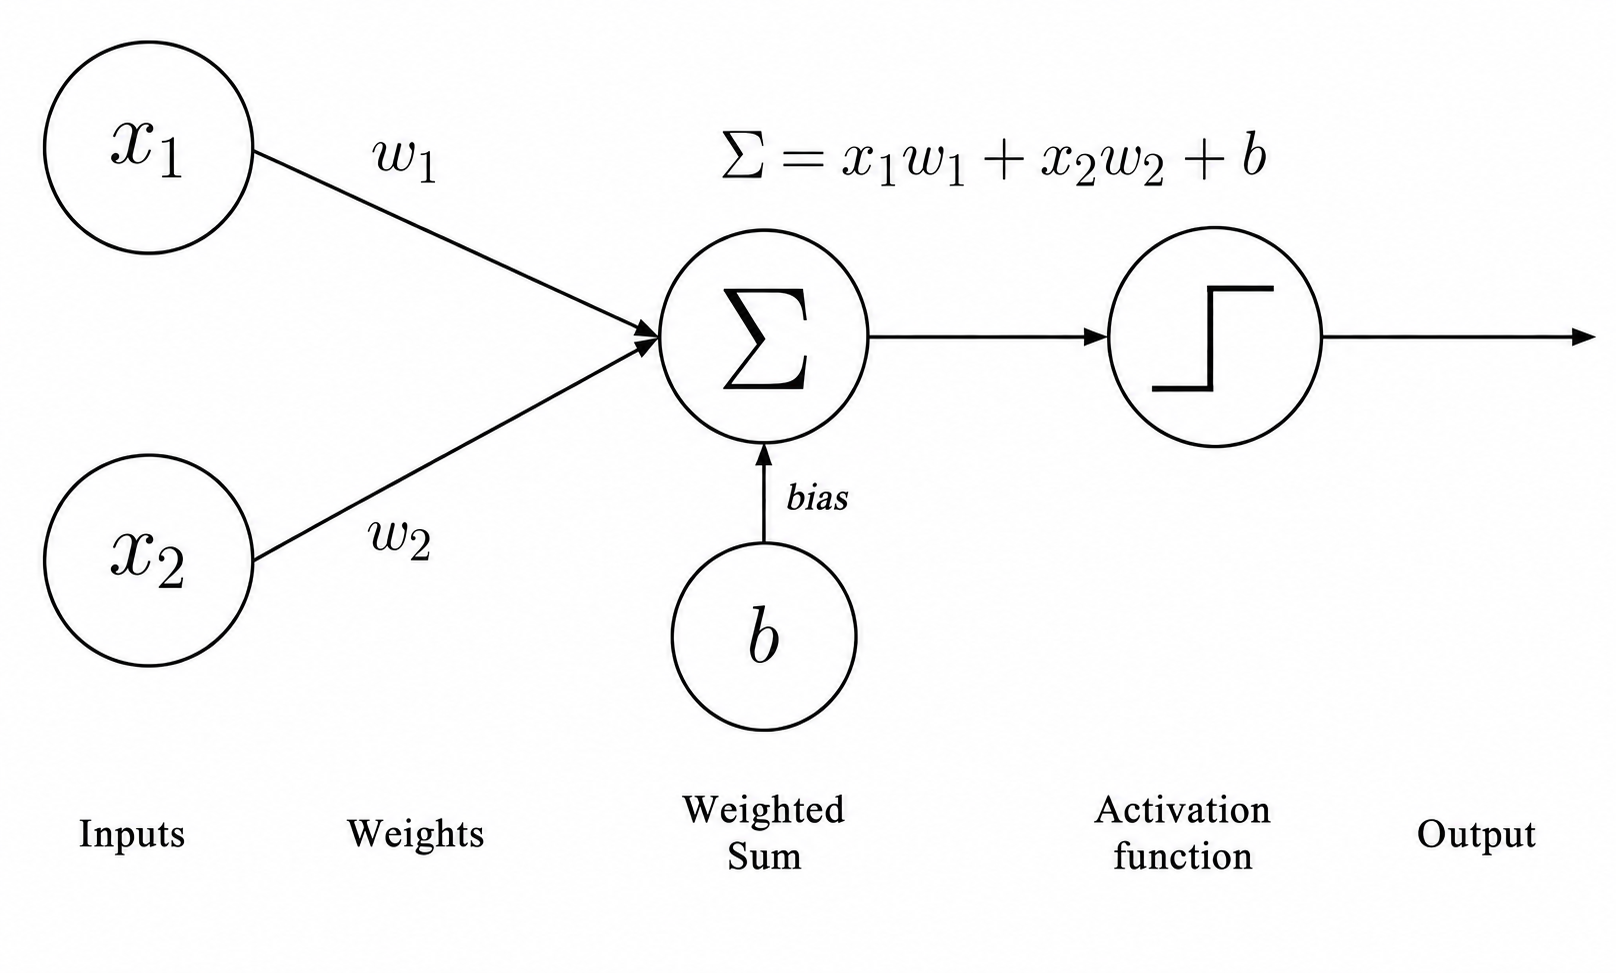

**Why "weight" is the right word:** each weight represents how much a
particular input should matter for the decision. A weight near zero means
"mostly ignore this input"; a large weight means "this input strongly
influences the outcome." Weights start out essentially random — the
network has no idea yet which of our 122 features matter. Training nudges
these weights toward values that reflect each feature's real importance.

**Why one perceptron isn't enough — the MLP (Multi-Layer Perceptron)**

A single perceptron can only draw a straight-line-style decision boundary
between classes — mathematically limited to linear relationships between
inputs and output. Real problems usually need more complex, curved
boundaries. The solution: stack many perceptrons into layers, and stack
multiple layers on top of each other:

- **Input layer:** not really neurons doing computation — just our 122
  feature values entering the network.
- **Hidden layer(s):** layers of perceptrons in between, each receiving
  the *previous* layer's outputs as its own inputs, computing its own
  weighted-sum-plus-activation, and passing results forward. "Hidden"
  just means we don't directly observe these intermediate values.
- **Output layer:** the final layer, producing our actual prediction —
  5 output values in our case, one per class.

**Why the activation function is non-negotiable:** if you stacked
multiple layers *without* an activation function, mathematically the
entire multi-layer network would collapse into being equivalent to a
single layer — no more powerful than one perceptron. Stacking linear
operations on top of each other is still just linear. The activation
function introduces **non-linearity** — the specific ingredient that lets
a multi-layer network learn curved, complex decision boundaries instead of
collapsing back into a straight line.

### Step 19: Designing the MLP Architecture

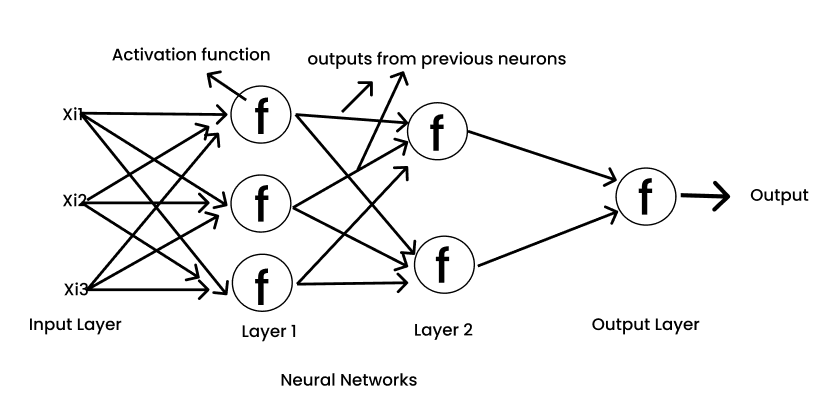

Two pieces of our architecture are fixed by the data itself, not chosen:

- **Input layer size = 122** — must exactly match `X_train`'s column
  count (38 scaled numeric + 84 one-hot categorical).
- **Output layer size = 5** — one output value per class (`DoS`, `Probe`,
  `R2L`, `U2R`, `normal`).

Everything *between* those two is our actual design decision: how many
hidden layers, how wide each one is, and which activation function to use.
We're starting with 2 hidden layers — 128 neurons, then 64 — using ReLU
activation. This isn't derived from a formula; it's a reasonable, common
starting point we can revisit once we see how training actually behaves.

**What a forward pass actually is**

A forward pass is the act of taking one input (in our case, a row of 122
feature values) and pushing it *through* every layer of the network, in
order, to produce a final output. "Forward" simply describes the
direction data travels — from the input layer, through each hidden layer
in sequence, to the output layer. No layer is skipped, and nothing flows
backward at this stage.

Concretely, for one row of input `x`:

$$h_1 = \text{ReLU}(W_1x + b_1)$$

$$h_2 = \text{ReLU}(W_2h_1 + b_2)$$

$$\text{logits} = W_3h_2 + b_3$$

Each layer takes the *previous* layer's output as its own input — `h_1`
(the first hidden layer's output) becomes the input to the second hidden
layer, and so on. This is exactly why matching shapes between layers
matters: the forward pass is a literal, mechanical chain of computations,
and a shape mismatch anywhere in that chain would break it immediately.

At this stage, the network's weights are still random — a forward pass
right now would produce a prediction, but not a meaningful one. Running
data through the network like this is a completely separate step from
adjusting those weights to make the predictions accurate; that comes later.

In [306]:
import torch.nn as nn

class IntrusionMLP(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 128)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(128, 64)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(64, num_classes)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu1(x)
        x = self.fc2(x)
        x = self.relu2(x)
        x = self.fc3(x)
        return x

model = IntrusionMLP(input_dim=122, num_classes=5)
print(model)

IntrusionMLP(
  (fc1): Linear(in_features=122, out_features=128, bias=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (relu2): ReLU()
  (fc3): Linear(in_features=64, out_features=5, bias=True)
)


### Step 20: Loss Function and Optimizer

Right now, our network can produce an output (a forward pass), but it has
no way to know if that output is good or bad, and no mechanism to improve
itself. Two things fix that:

- **Loss function** — a formula that measures exactly how wrong the
  network's prediction was, compared to the true label, as a single number.
- **Optimizer** — the algorithm that uses that "wrongness" number to
  actually adjust the network's weights, nudging them to make future
  predictions less wrong.

We're using **CrossEntropyLoss** for the loss function, and **Adam** for
the optimizer — both standard, well-established defaults for a multi-class
classification problem like ours.

In [307]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(criterion)
print(optimizer)

CrossEntropyLoss()
Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


### Step 21: Tensors and Batching

PyTorch doesn't work directly with NumPy arrays or pandas data — it needs
its own data structure called a **tensor**. A tensor is essentially the
same idea as a NumPy array (a grid of numbers), but with extra abilities
PyTorch needs: tracking operations for automatic gradient computation, and
running efficiently on CPU or GPU. So our first job is converting
`X_train`, `y_train`, `X_test`, `y_test` into tensors.

Second, we need to decide how data gets fed into the network. We won't
feed all 125,973 rows through the network at once — instead, we split
the training data into smaller chunks called **batches**, and feed one
batch at a time. This matters for two practical reasons: processing
all rows simultaneously would require holding every intermediate
calculation for all 125,973 rows in memory at once, and smaller batches
mean the optimizer updates the weights more frequently, using slightly
different subsets of data each time.

In [308]:
import torch
from torch.utils.data import TensorDataset, DataLoader

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

print("X_train_tensor shape:", X_train_tensor.shape)
print("y_train_tensor shape:", y_train_tensor.shape)
print("Number of batches:", len(train_loader))

X_train_tensor shape: torch.Size([125973, 122])
y_train_tensor shape: torch.Size([125973])
Number of batches: 1969


### Step 22: The Training Loop

One **epoch** means one complete pass through the entire training set —
in our case, all 1,969 batches, once each. We'll train for several
epochs, since a single pass usually isn't enough for the network to
learn well.

For every single batch, the same five things happen in order:

1. **Zero the gradients** — clear out leftover gradient values from the
   previous batch, so they don't accumulate incorrectly.
2. **Forward pass** — run the batch's inputs through the network to get
   predictions (logits).
3. **Compute loss** — measure how wrong those predictions were, using
   `CrossEntropyLoss`.
4. **Backward pass** — calculate, for every weight in the network, how
   much it contributed to that loss (this is backpropagation).
5. **Optimizer step** — actually update every weight, using those
   calculated contributions, to reduce the loss.

This five-step cycle repeats for every batch, every epoch.

In [309]:
num_epochs = 10

for epoch in range(num_epochs):
    total_loss = 0.0

    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()

        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    print(f"Epoch {epoch+1}/{num_epochs} - Average Loss: {avg_loss:.4f}")

Epoch 1/10 - Average Loss: 0.0636
Epoch 2/10 - Average Loss: 0.0217
Epoch 3/10 - Average Loss: 0.0181
Epoch 4/10 - Average Loss: 0.0165
Epoch 5/10 - Average Loss: 0.0145
Epoch 6/10 - Average Loss: 0.0133
Epoch 7/10 - Average Loss: 0.0123
Epoch 8/10 - Average Loss: 0.0120
Epoch 9/10 - Average Loss: 0.0116
Epoch 10/10 - Average Loss: 0.0105


### Step 23: Evaluate on Test Set

The network has only ever seen training data so far. Now we run it on
`X_test`/`y_test` — data it has never touched during training — using
**overall accuracy** first, then a breakdown per class next step, since
we already know accuracy alone can hide poor performance on rare classes.

Two important differences from training, both necessary:

- **`model.eval()`** — switches the model into evaluation mode. Some
  layers (not currently in our architecture, but common in more advanced
  ones) behave differently during training versus evaluation; setting
  this explicitly is standard practice regardless.
- **`torch.no_grad()`** — tells PyTorch not to track gradients for this
  computation. We're not going to call `.backward()` here, so tracking
  gradients would just waste memory and computation for no reason.

In [310]:
model.eval()

with torch.no_grad():
    test_outputs = model(X_test_tensor)
    test_loss = criterion(test_outputs, y_test_tensor)
    _, predicted = torch.max(test_outputs, dim=1)
    correct = (predicted == y_test_tensor).sum().item()
    accuracy = correct / len(y_test_tensor)

print("Test Loss:", test_loss.item())
print("Test Accuracy:", accuracy)

Test Loss: 3.127903699874878
Test Accuracy: 0.761222498225692


### Step 24: Visualize Training Loss

Numbers in a printed list are hard to read trends from. A plotted curve
makes the pattern immediate: is loss dropping steadily, has it plateaued,
did it spike anywhere unexpectedly? Since our training loop didn't save
per-epoch loss values, we add that now and re-run training — the fixed
seed from Step 2 means this re-run should reproduce the same 10 loss
values as before.

In [311]:
torch.manual_seed(SEED)
model = IntrusionMLP(input_dim=122, num_classes=5)
optimizer = optim.Adam(model.parameters(), lr=0.001)

num_epochs = 10
train_losses = []

for epoch in range(num_epochs):
    total_loss = 0.0
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    avg_loss = total_loss / len(train_loader)
    train_losses.append(avg_loss)
    print(f"Epoch {epoch+1}/{num_epochs} - Average Loss: {avg_loss:.4f}")

Epoch 1/10 - Average Loss: 0.0636
Epoch 2/10 - Average Loss: 0.0217
Epoch 3/10 - Average Loss: 0.0181
Epoch 4/10 - Average Loss: 0.0165
Epoch 5/10 - Average Loss: 0.0145
Epoch 6/10 - Average Loss: 0.0133
Epoch 7/10 - Average Loss: 0.0123
Epoch 8/10 - Average Loss: 0.0120
Epoch 9/10 - Average Loss: 0.0116
Epoch 10/10 - Average Loss: 0.0105


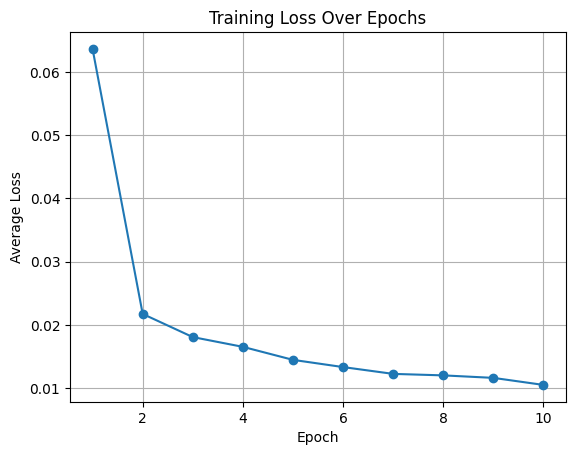

In [312]:
import matplotlib.pyplot as plt

plt.plot(range(1, num_epochs + 1), train_losses, marker='o')
plt.xlabel('Epoch')
plt.ylabel('Average Loss')
plt.title('Training Loss Over Epochs')
plt.grid(True)
plt.show()

### Progress Summary (Steps 16–24)

**Step 16 — Build Target Labels:** Converted the specific attack names in
the `label` column into our 5 agreed categories (`normal`, `DoS`, `Probe`,
`R2L`, `U2R`), then turned those 5 category names into plain numbers
(0-4), since a model can only work with numbers, not words.

**Step 17 — Baseline Model:** Built two simple, non-neural-network
reference points before touching the real model: one that always guesses
the most common category (scored 43.1%), and a basic classical model,
Logistic Regression (scored 76.1%). These numbers set the floor and a
real bar our actual model needs to beat.

**Step 18 — Understanding the Perceptron and MLP (Theory):** Learned what
a single artificial neuron actually does — take some numbers in, multiply
each by a weight, add a bias, pass it through an activation function — and
why stacking many of these into layers (with activation functions in
between) lets a network learn far more complex patterns than one neuron
alone ever could.

**Step 19 — Designing the MLP Architecture:** Built our actual network in
code: 122 inputs in, 2 hidden layers (128 neurons, then 64) using ReLU
activation, narrowing down to 5 outputs — one per class. Also covered what
a "forward pass" means: pushing one row of data through every layer, in
order, to get a prediction.

**Step 20 — Loss Function and Optimizer:** Set up the two pieces that let
the network actually learn: a loss function (`CrossEntropyLoss`) that
measures exactly how wrong a prediction was, and an optimizer (`Adam`)
that uses that measurement to adjust the network's weights.

**Step 21 — Tensors and Batching:** Converted our data into PyTorch's
required format (tensors), and set up feeding it to the network in small
chunks (batches of 64 rows) rather than all 125,973 rows at once.

**Step 22 — The Training Loop:** Ran the network through the training data
10 full times (10 epochs). Watched the loss drop sharply at first, then
level off — direct evidence the network was genuinely learning from the
data batch by batch.

**Step 23 — Evaluate on Test Set:** Tested the trained network on data it
had never seen before. Training loss was extremely low, but test accuracy
came out to 76.1% — essentially tied with plain Logistic Regression. This
revealed the network had mostly memorized the training data rather than
learning patterns general enough to transfer well to new, unseen data.

**Step 24 — Visualize Training Loss:** Plotted the 10 epoch-by-epoch loss
values on a graph, making the steep-drop-then-flatten learning pattern
immediately visible, and confirmed our fixed seed genuinely reproduces the
exact same training run every time, by re-running training from a fresh
start and getting identical numbers.



### Step 25: Per-Class Evaluation

Overall accuracy treats every prediction equally, but our classes are
severely imbalanced — getting `normal` or `DoS` right (the common
classes) barely tells us anything, while getting `U2R` or `R2L` right
(the rare classes) is much harder and arguably more important. We need
two new metrics, computed separately per class:

- **Precision** — of everything the model labeled as class X, what
  fraction actually was class X? Low precision means lots of false alarms
  for that class.
- **Recall** — of everything that actually was class X, what fraction did
  the model correctly catch? Low recall means the model is missing that
  class often, letting it slip through undetected.

We'll also build a **confusion matrix** — a table showing exactly which
classes get mistaken for which others, not just an overall right/wrong
count.

In [313]:
from sklearn.metrics import classification_report, confusion_matrix

class_names = label_encoder.classes_

print(classification_report(y_test_tensor, predicted, target_names=class_names))

              precision    recall  f1-score   support

         DoS       0.96      0.82      0.89      7460
       Probe       0.70      0.68      0.69      2421
         R2L       0.97      0.07      0.12      2885
         U2R       0.91      0.15      0.26        67
      normal       0.67      0.94      0.79      9711

    accuracy                           0.76     22544
   macro avg       0.84      0.53      0.55     22544
weighted avg       0.81      0.76      0.72     22544



### Step 26: Confusion Matrix

The classification report told us R2L and U2R have very low recall — the
model is missing most real instances of these attacks. A confusion matrix
shows exactly what the model predicted *instead*, for every true class —
turning "the model is missing R2L" into "the model is calling most real
R2L attacks `normal`" (or whatever the data actually shows), with direct
evidence rather than inference.

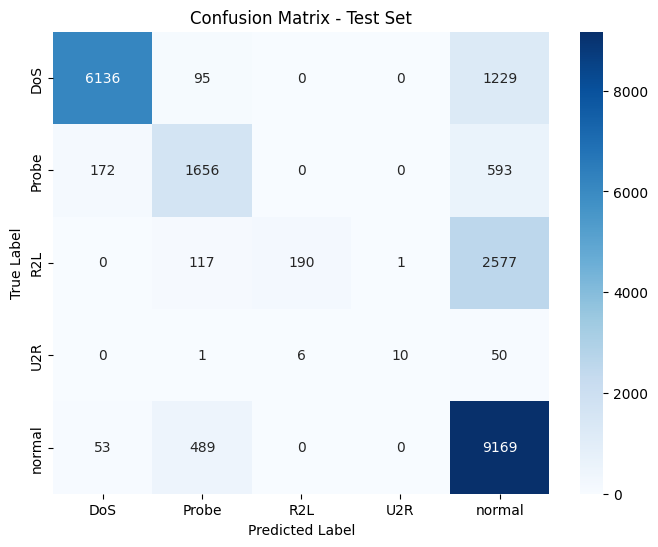

In [314]:
import seaborn as sns

cm = confusion_matrix(y_test_tensor, predicted)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Test Set')
plt.show()

### Step 27: Class-Weighted Loss

Right now, `CrossEntropyLoss` treats every misclassification equally —
getting one U2R row wrong "costs" the same as getting one DoS row wrong,
even though U2R has only 67 test examples against DoS's 7,460. With no
extra pressure to learn the rare classes, the network took the easy route:
default to `normal` whenever uncertain, since that's usually right often
enough to keep overall loss low.

We fix this by passing `CrossEntropyLoss` a **weight per class** — a
multiplier applied to the loss whenever that class is the true label.
Rare classes get a higher weight, so mistakes on them are penalized more
heavily, giving the optimizer real pressure to learn their patterns rather
than ignoring them as statistically safe to guess wrong on.

We'll compute weights as **inversely proportional to class frequency** —
rarer classes get proportionally higher weight.

In [315]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32)

print("Class weights:", dict(zip(class_names, class_weights)))

Class weights: {'DoS': np.float64(0.5485792670977856), 'Probe': np.float64(2.1615133836650653), 'R2L': np.float64(25.321206030150755), 'U2R': np.float64(484.51153846153846), 'normal': np.float64(0.3741235169208381)}


### Step 28: Retrain with Class-Weighted Loss

We create a fresh model (same architecture as before) and a new
`CrossEntropyLoss`, this time passing in `class_weights_tensor`. Everything
else — epochs, batch size, optimizer, learning rate — stays identical to
the original run, so any difference in results can be attributed to the
weighting change alone, not some other accidental variable.

In [316]:
torch.manual_seed(SEED)
model_weighted = IntrusionMLP(input_dim=122, num_classes=5)
optimizer_weighted = optim.Adam(model_weighted.parameters(), lr=0.001)
criterion_weighted = nn.CrossEntropyLoss(weight=class_weights_tensor)

num_epochs = 10
train_losses_weighted = []

for epoch in range(num_epochs):
    total_loss = 0.0
    for batch_X, batch_y in train_loader:
        optimizer_weighted.zero_grad()
        outputs = model_weighted(batch_X)
        loss = criterion_weighted(outputs, batch_y)
        loss.backward()
        optimizer_weighted.step()
        total_loss += loss.item()
    avg_loss = total_loss / len(train_loader)
    train_losses_weighted.append(avg_loss)
    print(f"Epoch {epoch+1}/{num_epochs} - Average Loss: {avg_loss:.4f}")

Epoch 1/10 - Average Loss: 0.1846
Epoch 2/10 - Average Loss: 0.0850
Epoch 3/10 - Average Loss: 0.0741
Epoch 4/10 - Average Loss: 0.0633
Epoch 5/10 - Average Loss: 0.0540
Epoch 6/10 - Average Loss: 0.0625
Epoch 7/10 - Average Loss: 0.0494
Epoch 8/10 - Average Loss: 0.0465
Epoch 9/10 - Average Loss: 0.0496
Epoch 10/10 - Average Loss: 0.0605


### Step 29: Evaluate Weighted Model and Compare

Run the same evaluation as Step 25/26, but on `model_weighted`. The real
question isn't just "did R2L/U2R recall improve" — it's whether that
improvement came at an acceptable cost elsewhere (more false positives on
`normal`, lower precision), or whether it's a genuine win across the board.

In [317]:
model_weighted.eval()

with torch.no_grad():
    test_outputs_weighted = model_weighted(X_test_tensor)
    _, predicted_weighted = torch.max(test_outputs_weighted, dim=1)

print("=== Original Model (unweighted loss) ===")
print(classification_report(y_test_tensor, predicted, target_names=class_names))

print("\n=== Weighted Model (class-weighted loss) ===")
print(classification_report(y_test_tensor, predicted_weighted, target_names=class_names))

=== Original Model (unweighted loss) ===
              precision    recall  f1-score   support

         DoS       0.96      0.82      0.89      7460
       Probe       0.70      0.68      0.69      2421
         R2L       0.97      0.07      0.12      2885
         U2R       0.91      0.15      0.26        67
      normal       0.67      0.94      0.79      9711

    accuracy                           0.76     22544
   macro avg       0.84      0.53      0.55     22544
weighted avg       0.81      0.76      0.72     22544


=== Weighted Model (class-weighted loss) ===
              precision    recall  f1-score   support

         DoS       0.95      0.77      0.85      7460
       Probe       0.74      0.70      0.72      2421
         R2L       0.94      0.17      0.29      2885
         U2R       0.07      0.43      0.12        67
      normal       0.69      0.95      0.80      9711

    accuracy                           0.76     22544
   macro avg       0.68      0.60      0.55 

### Step 30: Dampened Class Weights

The "balanced" formula scales weight directly and linearly with rarity —
which is exactly why U2R (67 test examples) got an extreme 484x
multiplier, overcorrecting the model into flagging far too many false
positives for that class. A common fix: apply a **square root** to the
raw balanced weights before using them. This preserves the same
ordering — rarer classes still get higher weight than common ones — but
compresses the extremes, so a class 900x rarer than another gets roughly
30x the weight instead of 900x, a much gentler push.

In [318]:
class_weights_sqrt = np.sqrt(class_weights)
class_weights_sqrt_tensor = torch.tensor(class_weights_sqrt, dtype=torch.float32)

print("Dampened class weights:", dict(zip(class_names, class_weights_sqrt)))

Dampened class weights: {'DoS': np.float64(0.7406613714092194), 'Probe': np.float64(1.4702086190963055), 'R2L': np.float64(5.0320180872241265), 'U2R': np.float64(22.01162280390836), 'normal': np.float64(0.6116563716016029)}


In [319]:
torch.manual_seed(SEED)
model_sqrt = IntrusionMLP(input_dim=122, num_classes=5)
optimizer_sqrt = optim.Adam(model_sqrt.parameters(), lr=0.001)
criterion_sqrt = nn.CrossEntropyLoss(weight=class_weights_sqrt_tensor)

num_epochs = 10
train_losses_sqrt = []

for epoch in range(num_epochs):
    total_loss = 0.0
    for batch_X, batch_y in train_loader:
        optimizer_sqrt.zero_grad()
        outputs = model_sqrt(batch_X)
        loss = criterion_sqrt(outputs, batch_y)
        loss.backward()
        optimizer_sqrt.step()
        total_loss += loss.item()
    avg_loss = total_loss / len(train_loader)
    train_losses_sqrt.append(avg_loss)
    print(f"Epoch {epoch+1}/{num_epochs} - Average Loss: {avg_loss:.4f}")

Epoch 1/10 - Average Loss: 0.1152
Epoch 2/10 - Average Loss: 0.0506
Epoch 3/10 - Average Loss: 0.0411
Epoch 4/10 - Average Loss: 0.0391
Epoch 5/10 - Average Loss: 0.0337
Epoch 6/10 - Average Loss: 0.0357
Epoch 7/10 - Average Loss: 0.0286
Epoch 8/10 - Average Loss: 0.0282
Epoch 9/10 - Average Loss: 0.0284
Epoch 10/10 - Average Loss: 0.0259


In [320]:
model_sqrt.eval()

with torch.no_grad():
    test_outputs_sqrt = model_sqrt(X_test_tensor)
    _, predicted_sqrt = torch.max(test_outputs_sqrt, dim=1)

print("=== Original Model (unweighted loss) ===")
print(classification_report(y_test_tensor, predicted, target_names=class_names))

print("\n=== Weighted Model (balanced, aggressive) ===")
print(classification_report(y_test_tensor, predicted_weighted, target_names=class_names))

print("\n=== Weighted Model (sqrt-dampened) ===")
print(classification_report(y_test_tensor, predicted_sqrt, target_names=class_names))

=== Original Model (unweighted loss) ===
              precision    recall  f1-score   support

         DoS       0.96      0.82      0.89      7460
       Probe       0.70      0.68      0.69      2421
         R2L       0.97      0.07      0.12      2885
         U2R       0.91      0.15      0.26        67
      normal       0.67      0.94      0.79      9711

    accuracy                           0.76     22544
   macro avg       0.84      0.53      0.55     22544
weighted avg       0.81      0.76      0.72     22544


=== Weighted Model (balanced, aggressive) ===
              precision    recall  f1-score   support

         DoS       0.95      0.77      0.85      7460
       Probe       0.74      0.70      0.72      2421
         R2L       0.94      0.17      0.29      2885
         U2R       0.07      0.43      0.12        67
      normal       0.69      0.95      0.80      9711

    accuracy                           0.76     22544
   macro avg       0.68      0.60      0.55

### Step 31: Oversample U2R in Training Data

Class weighting didn't fix U2R's precision problem, even after dampening —
suggesting the issue isn't just "the loss doesn't care enough," but that
52 training examples may simply be too few for the network to learn a
reliable pattern at all. Oversampling addresses this differently: instead
of reweighting the loss, we duplicate U2R's actual training rows several
times, so the network encounters them repeatedly across each epoch,
directly increasing how many gradient updates are shaped by real U2R data.

One honest limitation to flag now: this duplicates *exact copies* of the
same 52 rows — it doesn't create new, varied examples the way more
advanced techniques (like SMOTE, which synthesizes interpolated points)
would. There's a real risk the network simply memorizes these 52 specific
rows rather than learning a generalizable U2R pattern — something we'll
need to watch for in the results, not assume away.

In [321]:
from collections import Counter

print("Original y_train class counts:", Counter(y_train))

u2r_class_index = list(class_names).index('U2R')
u2r_indices = np.where(y_train == u2r_class_index)[0]

oversample_factor = 20
u2r_oversampled_indices = np.tile(u2r_indices, oversample_factor)

X_train_oversampled = np.vstack([X_train, X_train[u2r_oversampled_indices]])
y_train_oversampled = np.concatenate([y_train, y_train[u2r_oversampled_indices]])

print("New y_train class counts:", Counter(y_train_oversampled))

Original y_train class counts: Counter({np.int64(4): 67343, np.int64(0): 45927, np.int64(1): 11656, np.int64(2): 995, np.int64(3): 52})
New y_train class counts: Counter({np.int64(4): 67343, np.int64(0): 45927, np.int64(1): 11656, np.int64(3): 1092, np.int64(2): 995})


In [322]:
X_train_oversampled_tensor = torch.tensor(X_train_oversampled, dtype=torch.float32)
y_train_oversampled_tensor = torch.tensor(y_train_oversampled, dtype=torch.long)

train_dataset_oversampled = TensorDataset(X_train_oversampled_tensor, y_train_oversampled_tensor)
train_loader_oversampled = DataLoader(train_dataset_oversampled, batch_size=64, shuffle=True)

print("Number of batches:", len(train_loader_oversampled))

Number of batches: 1985


In [323]:
torch.manual_seed(SEED)
model_oversampled = IntrusionMLP(input_dim=122, num_classes=5)
optimizer_oversampled = optim.Adam(model_oversampled.parameters(), lr=0.001)
criterion_oversampled = nn.CrossEntropyLoss()

num_epochs = 10
train_losses_oversampled = []

for epoch in range(num_epochs):
    total_loss = 0.0
    for batch_X, batch_y in train_loader_oversampled:
        optimizer_oversampled.zero_grad()
        outputs = model_oversampled(batch_X)
        loss = criterion_oversampled(outputs, batch_y)
        loss.backward()
        optimizer_oversampled.step()
        total_loss += loss.item()
    avg_loss = total_loss / len(train_loader_oversampled)
    train_losses_oversampled.append(avg_loss)
    print(f"Epoch {epoch+1}/{num_epochs} - Average Loss: {avg_loss:.4f}")

Epoch 1/10 - Average Loss: 0.0724
Epoch 2/10 - Average Loss: 0.0261
Epoch 3/10 - Average Loss: 0.0219
Epoch 4/10 - Average Loss: 0.0192
Epoch 5/10 - Average Loss: 0.0181
Epoch 6/10 - Average Loss: 0.0177
Epoch 7/10 - Average Loss: 0.0148
Epoch 8/10 - Average Loss: 0.0147
Epoch 9/10 - Average Loss: 0.0136
Epoch 10/10 - Average Loss: 0.0130


In [324]:
model_oversampled.eval()

with torch.no_grad():
    test_outputs_oversampled = model_oversampled(X_test_tensor)
    _, predicted_oversampled = torch.max(test_outputs_oversampled, dim=1)

print("=== Original Model (unweighted loss) ===")
print(classification_report(y_test_tensor, predicted, target_names=class_names))

print("\n=== Weighted Model (sqrt-dampened) ===")
print(classification_report(y_test_tensor, predicted_sqrt, target_names=class_names))

print("\n=== Oversampled Model (U2R x20) ===")
print(classification_report(y_test_tensor, predicted_oversampled, target_names=class_names))

=== Original Model (unweighted loss) ===
              precision    recall  f1-score   support

         DoS       0.96      0.82      0.89      7460
       Probe       0.70      0.68      0.69      2421
         R2L       0.97      0.07      0.12      2885
         U2R       0.91      0.15      0.26        67
      normal       0.67      0.94      0.79      9711

    accuracy                           0.76     22544
   macro avg       0.84      0.53      0.55     22544
weighted avg       0.81      0.76      0.72     22544


=== Weighted Model (sqrt-dampened) ===
              precision    recall  f1-score   support

         DoS       0.95      0.75      0.84      7460
       Probe       0.77      0.71      0.74      2421
         R2L       0.96      0.11      0.20      2885
         U2R       0.08      0.34      0.13        67
      normal       0.68      0.96      0.80      9711

    accuracy                           0.76     22544
   macro avg       0.69      0.58      0.54     22

### Step 32: Oversample R2L as Well

Oversampling fixed U2R without harming other classes, but R2L is still
essentially undetected (recall 0.09). We apply the same technique to R2L,
combined with the existing U2R oversampling, and retrain — testing
whether the same fix that worked for one extreme-minority class transfers
to another.

In [325]:
r2l_class_index = list(class_names).index('R2L')
r2l_indices = np.where(y_train == r2l_class_index)[0]

r2l_oversample_factor = 4
r2l_oversampled_indices = np.tile(r2l_indices, r2l_oversample_factor)

X_train_oversampled2 = np.vstack([X_train_oversampled, X_train[r2l_oversampled_indices]])
y_train_oversampled2 = np.concatenate([y_train_oversampled, y_train[r2l_oversampled_indices]])

print("Final class counts:", Counter(y_train_oversampled2))

Final class counts: Counter({np.int64(4): 67343, np.int64(0): 45927, np.int64(1): 11656, np.int64(2): 4975, np.int64(3): 1092})


In [326]:
X_train_oversampled2_tensor = torch.tensor(X_train_oversampled2, dtype=torch.float32)
y_train_oversampled2_tensor = torch.tensor(y_train_oversampled2, dtype=torch.long)

train_dataset_oversampled2 = TensorDataset(X_train_oversampled2_tensor, y_train_oversampled2_tensor)
train_loader_oversampled2 = DataLoader(train_dataset_oversampled2, batch_size=64, shuffle=True)

print("Number of batches:", len(train_loader_oversampled2))

Number of batches: 2047


In [327]:
torch.manual_seed(SEED)
model_oversampled2 = IntrusionMLP(input_dim=122, num_classes=5)
optimizer_oversampled2 = optim.Adam(model_oversampled2.parameters(), lr=0.001)
criterion_oversampled2 = nn.CrossEntropyLoss()

num_epochs = 10
train_losses_oversampled2 = []

for epoch in range(num_epochs):
    total_loss = 0.0
    for batch_X, batch_y in train_loader_oversampled2:
        optimizer_oversampled2.zero_grad()
        outputs = model_oversampled2(batch_X)
        loss = criterion_oversampled2(outputs, batch_y)
        loss.backward()
        optimizer_oversampled2.step()
        total_loss += loss.item()
    avg_loss = total_loss / len(train_loader_oversampled2)
    train_losses_oversampled2.append(avg_loss)
    print(f"Epoch {epoch+1}/{num_epochs} - Average Loss: {avg_loss:.4f}")

Epoch 1/10 - Average Loss: 0.0870
Epoch 2/10 - Average Loss: 0.0344
Epoch 3/10 - Average Loss: 0.0286
Epoch 4/10 - Average Loss: 0.0251
Epoch 5/10 - Average Loss: 0.0226
Epoch 6/10 - Average Loss: 0.0201
Epoch 7/10 - Average Loss: 0.0193
Epoch 8/10 - Average Loss: 0.0172
Epoch 9/10 - Average Loss: 0.0156
Epoch 10/10 - Average Loss: 0.0163


In [328]:
model_oversampled2.eval()

with torch.no_grad():
    test_outputs_oversampled2 = model_oversampled2(X_test_tensor)
    _, predicted_oversampled2 = torch.max(test_outputs_oversampled2, dim=1)

print("=== Original Model (unweighted loss) ===")
print(classification_report(y_test_tensor, predicted, target_names=class_names))

print("\n=== Oversampled Model (U2R x20 only) ===")
print(classification_report(y_test_tensor, predicted_oversampled, target_names=class_names))

print("\n=== Oversampled Model (U2R x20 + R2L x4) ===")
print(classification_report(y_test_tensor, predicted_oversampled2, target_names=class_names))

=== Original Model (unweighted loss) ===
              precision    recall  f1-score   support

         DoS       0.96      0.82      0.89      7460
       Probe       0.70      0.68      0.69      2421
         R2L       0.97      0.07      0.12      2885
         U2R       0.91      0.15      0.26        67
      normal       0.67      0.94      0.79      9711

    accuracy                           0.76     22544
   macro avg       0.84      0.53      0.55     22544
weighted avg       0.81      0.76      0.72     22544


=== Oversampled Model (U2R x20 only) ===
              precision    recall  f1-score   support

         DoS       0.96      0.84      0.89      7460
       Probe       0.68      0.69      0.69      2421
         R2L       0.97      0.09      0.17      2885
         U2R       0.64      0.31      0.42        67
      normal       0.68      0.92      0.78      9711

    accuracy                           0.76     22544
   macro avg       0.78      0.57      0.59     

### Step 33: Final Model Selection

Across five attempts, we tested different ways to address the model's
poor performance on rare attack classes:

| Model                          | R2L Recall | U2R Precision | U2R Recall | Macro F1 |
|---------------------------------|-----------|---------------|-----------|----------|
| Original (unweighted)           | 0.07      | 0.91          | 0.15      | 0.55     |
| Class-weighted (aggressive)     | 0.17      | 0.07          | 0.43      | 0.55     |
| Class-weighted (sqrt-dampened)  | 0.11      | 0.08          | 0.34      | 0.54     |
| Oversampled (U2R only)          | 0.09      | 0.64          | 0.31      | **0.59** |
| Oversampled (U2R + R2L)         | 0.11      | 0.11          | 0.37      | 0.52     |

**Decision: the U2R-only oversampled model is our final model.** It gave
U2R a genuine, balanced improvement (both precision and recall improved
meaningfully) without meaningfully harming DoS, Probe, or normal — the
only attempt that improved a rare class without a serious tradeoff
elsewhere. It has the best macro F1 of all five attempts.

**Known, documented limitation:** R2L remains poorly detected (recall
~0.07-0.17 across all attempts) regardless of technique. This appears to
be a genuine, hard constraint of this dataset — many of R2L's real-world
attack types are entirely absent from training (per Step 7's findings),
and even direct oversampling of the existing 995 R2L examples didn't
meaningfully help. This is reported as an honest limitation of the final
model, not something resolved.

### Step 34: Save the Final Model

Right now, `model_oversampled` only exists in this Colab session's memory
— if the runtime disconnects or we close the tab, it's gone, along with
all the training it took to get here. We save its learned weights to a
file, so it can be reloaded later without retraining from scratch.

PyTorch's standard practice is saving the model's **state dictionary**
(`state_dict`) — a mapping of every layer's name to its actual learned
weight and bias values — rather than the whole Python object. This is
the recommended approach because it's more portable and stable across
PyTorch versions than saving the full object directly.

In [330]:
torch.save(model_oversampled.state_dict(), 'intrusion_mlp_final.pth')
print("Model saved.")

import os
print("File size (KB):", round(os.path.getsize('intrusion_mlp_final.pth') / 1024, 2))

Model saved.
File size (KB): 98.1


### Step 35: Inference on Sample Rows

Until now, we've only looked at aggregate metrics — accuracy, precision,
recall across thousands of rows at once. This step picks a handful of
individual test rows and runs them through the model one at a time, to
see concretely what a real prediction looks like.

One piece we've deliberately avoided until now: our model's raw output
(`logits`) are just 5 unbounded numbers, not probabilities — they don't
sum to 1, and a value like `-2.3` isn't intuitively meaningful on its own.
**Softmax** converts logits into an actual probability distribution:
5 numbers, each between 0 and 1, summing to exactly 1 — directly
interpretable as "the model is 87% confident this is normal traffic,"
for example. We use softmax here purely to make predictions *readable*;
recall this exact function is already applied internally by
`CrossEntropyLoss` during training, so nothing about the trained model
itself changes — we're just applying the same transformation manually now,
for display purposes.

In [331]:
import torch.nn.functional as F

sample_indices = [0, 1, 2, 3, 4]

model_oversampled.eval()
with torch.no_grad():
    sample_inputs = X_test_tensor[sample_indices]
    sample_true_labels = y_test_tensor[sample_indices]

    sample_logits = model_oversampled(sample_inputs)
    sample_probs = F.softmax(sample_logits, dim=1)
    sample_preds = torch.argmax(sample_probs, dim=1)

for i, idx in enumerate(sample_indices):
    true_class = class_names[sample_true_labels[i]]
    pred_class = class_names[sample_preds[i]]
    confidence = sample_probs[i][sample_preds[i]].item()

    print(f"Row {idx}: True = {true_class}, Predicted = {pred_class}, Confidence = {confidence:.2%}")

Row 0: True = DoS, Predicted = DoS, Confidence = 100.00%
Row 1: True = DoS, Predicted = DoS, Confidence = 100.00%
Row 2: True = normal, Predicted = normal, Confidence = 99.98%
Row 3: True = Probe, Predicted = Probe, Confidence = 100.00%
Row 4: True = Probe, Predicted = normal, Confidence = 100.00%


### Progress Summary (Steps 25–35)

**Step 25 — Per-Class Evaluation:** Went beyond overall accuracy and
checked precision/recall for each class individually. Found that DoS and
normal performed well, but R2L and U2R were badly broken — R2L had 97%
precision but only 7% recall, meaning the model almost never flagged real
R2L attacks at all, despite being right when it did.

**Step 26 — Confusion Matrix:** Visualized exactly what the model
predicted instead of the correct answer. Confirmed the failure directly:
nearly 90% of real R2L attacks, and most U2R attacks, were being labeled
`normal` — the model was defaulting to "safe" guesses whenever it faced a
rare attack type it hadn't learned well.

**Step 27 — Class-Weighted Loss:** Learned that misclassifying a rare
class was costing the model the same as misclassifying a common one,
giving it no real incentive to learn rare patterns. Computed weights that
penalize mistakes on rare classes (R2L, U2R) far more heavily than common
ones (DoS, normal).

**Step 28 — Retrain with Class-Weighted Loss:** Retrained a fresh model
using those weights. Training loss looked higher and noisier than before
— expected, since rare-class mistakes were now deliberately amplified.

**Step 29 — Evaluate Weighted Model and Compare:** R2L's recall improved
meaningfully (7% → 17%), but U2R's precision collapsed from 91% to 7% —
the model started crying "U2R" far too often, mostly incorrectly. A real,
imperfect tradeoff, not a clean fix.

**Step 30 — Dampened Class Weights:** Tried softening the most extreme
weight (U2R's, which was 484x) using a square root, hoping to keep the
benefit without the side effect. Result: R2L's improvement partially
reversed, and U2R's precision problem barely improved — revealing that
loss weighting alone couldn't fix U2R's core issue.

**Step 31 — Oversample U2R in Training Data:** Switched techniques
entirely: instead of changing the loss, duplicated U2R's ~52 real training
rows 20 times so the network saw them repeatedly. This worked — U2R's
precision recovered to 64% and recall nearly doubled to 31%, with no real
harm to other classes. Our best single change so far.

**Step 32 — Oversample R2L as Well:** Tried extending the same technique
to R2L. Result: R2L barely improved, and U2R's gains partially reversed —
combining oversampling across two classes at once destabilized training
rather than compounding the benefit.

**Step 33 — Final Model Selection:** Compared all five attempts side by
side and chose the U2R-only oversampled model as final — it gave the best
balanced improvement without harming other classes. Documented R2L's poor
performance as a genuine, unresolved limitation of this dataset and
approach, not something we forced a fix for.

**Step 34 — Save the Final Model:** Saved the chosen model's learned
weights to a file (`intrusion_mlp_final.pth`), so it can be reloaded later
without retraining from scratch.

**Step 35 — Inference on Sample Rows:** Ran the final model on a handful
of individual test rows to see real predictions. Four out of five were
correct with near-total confidence; one row was a real Probe attack
confidently (100%) misclassified as normal — a concrete, visible example
of the model's genuine limitations, not just an abstract percentage.

### Final Summary: What We Built and What We Learned

**The project:** an MLP that classifies network connection records as
`normal` or one of 4 attack categories (`DoS`, `Probe`, `R2L`, `U2R`),
using the NSL-KDD dataset — chosen specifically because its test set is
deliberately harder and differently distributed from training, creating a
real, observable generalization gap rather than a hypothetical one.

**What the final model achieves:** 76% overall test accuracy — matching
plain Logistic Regression, but with a meaningfully different, more
detailed breakdown per class:

- **DoS (96% precision, 82% recall)** and **normal (67% precision, 94%
  recall)** — strong, reliable performance.
- **Probe (70%/68%)** — moderate, workable performance.
- **U2R (64% precision, 31% recall after oversampling)** — genuinely
  improved from a near-unusable starting point (15% recall), through
  targeted oversampling of its ~52 training examples.
- **R2L (97% precision, 9% recall)** — the project's clearest unresolved
  limitation. When the model does flag R2L, it's almost always right —
  but it misses the vast majority of real R2L attacks, largely because
  many R2L attack types in the test set were entirely absent from
  training.

**What we learned building this, concretely:**
- How a perceptron and multi-layer network compute a prediction, and why
  activation functions are what make multiple layers meaningfully more
  powerful than one.
- How a loss function and optimizer work together to actually adjust a
  network's weights, and what a training loop's five-step cycle
  (zero gradients → forward pass → compute loss → backward pass →
  optimizer step) is doing on every single batch.
- That a low training loss does not imply good generalization — our
  first model's training loss dropped to 0.0105, while its test loss sat
  at 3.13, a direct, measured demonstration of overfitting rather than an
  abstract warning.
- That overall accuracy can hide serious per-class failures entirely —
  76% accuracy looked respectable until per-class metrics revealed R2L
  and U2R were almost completely undetected.
- That fixing class imbalance isn't a single settled technique — we
  tried class weighting (aggressive and dampened) and oversampling,
  observed real, different tradeoffs for each, and learned that a
  technique working for one rare class doesn't guarantee it works the
  same way for another, or in combination.

**What's genuinely unresolved:** R2L detection remains weak across every
technique tried. This appears to be a real data limitation — R2L has
relatively few training examples, and several of its test-time attack
types were never seen during training at all — rather than something a
different loss function or resampling ratio would cleanly fix. Documented
here as an honest constraint of this specific approach, not glossed over.